One way of identifying targets may be to look our interaction network and pick out proteins that interact similarly to our target pep5. The idea here is that if a protein has a similar interaction profile, then it may be able to fullfil a similar role.

In [56]:
import os
while "src" not in os.listdir():
    os.chdir("..")
    
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import mygene

from src.reading_in import read_in_proteins

In [57]:
PEP5 = "YMR231W"

G = read_in_proteins(connected=True)

In order to normalise, use Jaccard similarity.

In [58]:
PEP3 = "YLR148W"
VAM6 = "YDL077C"

mg = mygene.MyGeneInfo() # check my proteins are correct
print(
mg.getgene(PEP5)['symbol'],
mg.getgene(PEP3)['symbol'],
mg.getgene(VAM6)['symbol']
)

PEP5 PEP3 VAM6


pep3: 0.7083333333333334
vam6: 0.38461538461538464


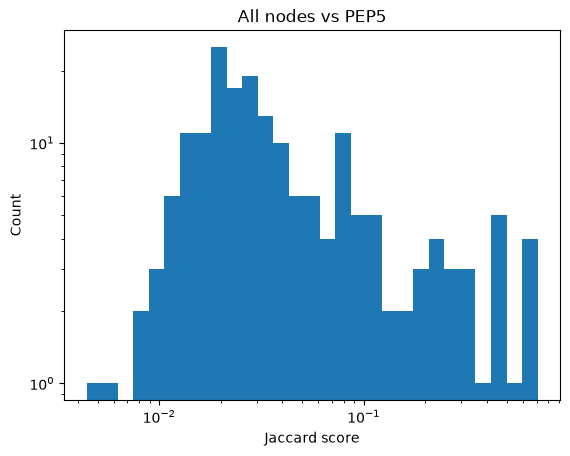


Distribution Stats (All nodes vs PEP5)
------------
zeros  : 5335 / 5520
mean   : 0.002770635973410455
median : 0.0
std    : 0.028400715792594577


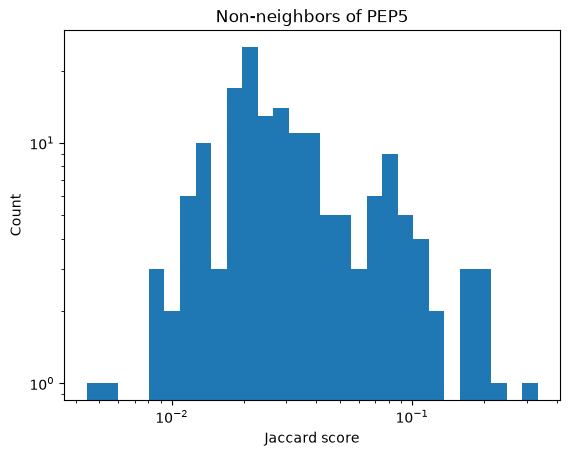


Distribution Stats (Non-neighbors of PEP5)
------------
zeros  : 5334 / 5499
mean   : 0.001340144420536827
median : 0.0
std    : 0.011223430077643825


In [59]:
import numpy as np
import matplotlib.pyplot as plt

def jaccard_for(G, source, exclude_neighbors=False):
    src_nbrs = set(G.neighbors(source))
    scores = {}
    for node in G:
        if node == source or (exclude_neighbors and node in src_nbrs):
            continue
        node_nbrs = set(G.neighbors(node))
        union = src_nbrs | node_nbrs
        scores[node] = len(src_nbrs & node_nbrs) / len(union) if union else 0
    return scores

def plot_and_summarize(scores, title):
    dist = np.array(list(scores.values()))
    pos = dist[dist > 0]  # log bins can't include zeros

    bins = np.logspace(np.log10(pos.min()), np.log10(pos.max()), 30)
    plt.hist(pos, bins=bins)
    plt.xscale("log")
    plt.yscale("log")
    plt.xlabel("Jaccard score")
    plt.ylabel("Count")
    plt.title(title)
    plt.show()

    print(f"\nDistribution Stats ({title})\n------------")
    print(f"zeros  : {np.sum(dist == 0)} / {len(dist)}")
    print(f"mean   : {dist.mean()}")
    print(f"median : {np.median(dist)}")
    print(f"std    : {dist.std()}")

# all nodes
scores_all = jaccard_for(G, PEP5)
print(f"pep3: {scores_all[PEP3]}")
print(f"vam6: {scores_all[VAM6]}")
plot_and_summarize(scores_all, "All nodes vs PEP5")

# non-neighbors only
scores_non = jaccard_for(G, PEP5, exclude_neighbors=True)
plot_and_summarize(scores_non, "Non-neighbors of PEP5")

This is actually built in!

In [60]:
preds = nx.jaccard_coefficient(G, [(PEP5, n) for n in G if n != PEP5 and not G.has_edge(PEP5, n)])
ranked_jaccard = sorted(preds, key=lambda x: x[2], reverse=True)  # (u, v, score)

We want nodes that are distance >= 4 away from pep5. Obviously at the moment we can only pick out nodes that are direct neighbours or 1 node away from our target. 

How can we adjust the method?

We are looking for proteins dist 3,4 or 5 away. So lets target those proteins.

In [61]:

# Parameters
MIN_DISTANCE = 3
MAX_DISTANCE = 5

df = pd.read_csv("data/raw/EssentialProteins_YeastMine_cerevisiae.csv")
df.columns = ['counter', 'systematic name', 'organism', 'standard name', 'description']

essential_proteins = list(df['systematic name'])


# Radius of neighbourhoods used for extended Jaccard similarity
K = 3

print(f"Number of proteins: {G.number_of_nodes()}")
print(f"Number of interactions: {G.number_of_edges()}")
print(f"Target: {PEP5}")

Number of proteins: 5521
Number of interactions: 91384
Target: YMR231W


In [62]:
# Shortest-path distances from Pep5
distances = nx.single_source_shortest_path_length(G, PEP5)

# Select proteins whose shortest-path distance is 3, 4, or 5
candidate_nodes = {
    node: distance
    for node, distance in distances.items()
    if MIN_DISTANCE <= distance <= MAX_DISTANCE
    and node not in essential_proteins # no essential proteins!
}

print(f"Number of candidate proteins: {len(candidate_nodes)}")

# Count candidates at each distance
for distance in range(MIN_DISTANCE, MAX_DISTANCE + 1):
    count = sum(
        d == distance
        for d in candidate_nodes.values()
    )
    print(f"Distance {distance}: {count} proteins")

Number of candidate proteins: 3736
Distance 3: 885 proteins
Distance 4: 2033 proteins
Distance 5: 818 proteins


In [63]:
communities = nx.community.louvain_communities(G, resolution=40, seed=0)

# Find the community containing Pep5
pep5_community = next(
    community for community in communities
    if PEP5 in community
)

print("Pep5 community size:", len(pep5_community))
print(pep5_community)

Pep5 community size: 29
{'YAL002W', 'YKR014C', 'YPL070W', 'YDR323C', 'YML001W', 'YBR131W', 'YMR231W', 'YDR080W', 'YPL199C', 'YDL077C', 'YPR176C', 'YML097C', 'YER123W', 'YBR264C', 'YJL031C', 'YER136W', 'YDR495C', 'YPL045W', 'YLR396C', 'YNL093W', 'YDR229W', 'YLR148W', 'YML003W', 'YPL236C', 'YOR370C', 'YOR089C', 'YML002W', 'YGL124C', 'YKL047W'}


In [64]:
def get_k_neighbourhood(G, node, k=3):
    """
    Return the set of all nodes within k edges of node,
    including node itself.
    """
    distances = nx.single_source_shortest_path_length(
        G, node, cutoff=k
    )

    return set(distances.keys())


def extended_jaccard(G, node1, node2, k=2):
    """
    Calculate Jaccard similarity between the k-step
    neighbourhoods of two nodes.
    """
    neighbourhood1 = get_k_neighbourhood(G, node1, k)
    neighbourhood2 = get_k_neighbourhood(G, node2, k)

    intersection = neighbourhood1 & neighbourhood2
    union = neighbourhood1 | neighbourhood2

    if len(union) == 0:
        return 0.0

    return len(intersection) / len(union)


# Calculate similarity between Pep5 and each candidate
jaccard_scores = {}

for node in candidate_nodes:
    jaccard_scores[node] = extended_jaccard(
        G, PEP5, node, k=K
    )

print("Top 10 candidates by extended Jaccard similarity:")

for node, score in sorted(
    jaccard_scores.items(),
    key=lambda x: x[1],
    reverse=True
)[:10]:
    print(
        f"{node}: "
        f"distance = {candidate_nodes[node]}, "
        f"similarity = {score:.4f}"
    )

Top 10 candidates by extended Jaccard similarity:
YER031C: distance = 3, similarity = 0.4668
YIL146C: distance = 3, similarity = 0.4544
YJL036W: distance = 3, similarity = 0.4512
YGL100W: distance = 3, similarity = 0.4470
YDL113C: distance = 3, similarity = 0.4452
YOL082W: distance = 3, similarity = 0.4400
YKL057C: distance = 3, similarity = 0.4307
YPL259C: distance = 3, similarity = 0.4293
YLR039C: distance = 3, similarity = 0.4260
YDR137W: distance = 3, similarity = 0.4233


In [65]:
jaccard_scores_filtered = {
    node : score 
    for node, score in jaccard_scores.items() 
    if candidate_nodes[node] >= 4
    }

for node, score in sorted(
    jaccard_scores_filtered.items(),
    key=lambda x: x[1],
    reverse=True
)[:10]:
    print(
        f"{node}: "
        f"distance = {candidate_nodes[node]}, "
        f"similarity = {score:.4f}"
    )

YOR216C: distance = 4, similarity = 0.4118
YKR036C: distance = 4, similarity = 0.4047
YML055W: distance = 4, similarity = 0.3934
YOR085W: distance = 4, similarity = 0.3894
YBR171W: distance = 4, similarity = 0.3870
YDR063W: distance = 4, similarity = 0.3850
YER048C: distance = 4, similarity = 0.3838
YGL178W: distance = 4, similarity = 0.3838
YJL073W: distance = 4, similarity = 0.3825
YDR358W: distance = 4, similarity = 0.3821


In [66]:
import scipy.stats as st
deg = dict(G.degree())
ball = {n: len(get_k_neighbourhood(G, n, 3)) for n in candidate_nodes}
nodes = list(candidate_nodes)
print(st.spearmanr([jaccard_scores[n] for n in nodes], [deg[n] for n in nodes]))
print(st.spearmanr([jaccard_scores[n] for n in nodes], [ball[n] for n in nodes]))

SignificanceResult(statistic=np.float64(0.7148198568473626), pvalue=np.float64(0.0))
SignificanceResult(statistic=np.float64(0.8712324760515954), pvalue=np.float64(0.0))
